# La diversification résiste-t-elle aux baisses de marché ?

**Projet Python ENSAE — Rapport final**

## Résumé

On compare six portefeuilles sur 2006–2025. Pendant les sept cycles de baisse retenus, les quatre allocations mixtes perdent moins que SPY, mais restent perdantes. Ajouter des pays protège de façon plus irrégulière. Un témoin à rendement nul montre qu'une partie de la protection vient simplement d'une moindre part actions ; l'apport des obligations varie et devient défavorable en 2022.

## 1. Introduction

On cherche à distinguer **perdre moins que le marché** et **préserver son capital pendant une baisse**. SPY, qui représente les grandes actions américaines, sert de référence. On examine ce que changent les actions internationales, les obligations et l'or, avec des allocations fixées pour toute la période.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

candidats = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidats
             if (p / "fonctions/scraping.py").is_file()
             and (p / "data/raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrir le notebook depuis le dossier du projet")
sys.path.insert(0, str(ROOT))

from fonctions.scraping import TICKERS, fetch_yahoo, fetch_fred
from fonctions.audit import auditer_prix, auditer_cpi
from fonctions.analyse import (
    ALLOCATIONS, simuler_allocations, capital_et_recul, indicateurs,
    pertes_en_baisse, reperer_episodes, rendements_episodes,
    contexte_inflation, comparer_temoin,
)
from fonctions.graphiques import tracer_capital, tracer_reculs, tracer_episodes, tracer_correlations


## 2. Données et préparation

On utilise six **ETF**, des fonds cotés : SPY pour les actions américaines, EFA pour les actions développées hors États-Unis et Canada, EEM pour les émergentes, IEF et SHY pour les obligations du Trésor américain à 7–10 ans et 1–3 ans, et GLD pour l'or.

Une action représente une part d'entreprise ; une obligation est une dette de son émetteur. On étudie **2006–2025**, avec le cours du **30 décembre 2005** pour calculer le premier rendement.

`scraping.py` collecte les cours avec `yf.download`, de fin 2005 au 1er janvier 2026 exclu. On garde séparément `Close` et `Adj Close` avec `auto_adjust=False`. Les cours ajustés approchent un rendement avec distributions réinvesties : on n'ajoute donc pas les dividendes une seconde fois.

Pour l'inflation, la sauvegarde fournie provient du **BLS**, série `CUSR0000SA0`, convertie en Parquet sans changer ses valeurs. La colonne est nommée `CPIAUCSL`, comme la série diffusée par FRED. `fetch_fred` permet une nouvelle collecte via FRED avec une clé personnelle. L'inflation sert uniquement à décrire le contexte.


In [2]:
informations = json.loads((ROOT / "data/raw/collecte.json").read_text())
sources = pd.DataFrame(informations["sources"])
display(sources)


,fichier,source,contenu,collecte_utc
0,asset_prices.parquet,Yahoo Finance via yfinance,cours ajustés des six ETF,2026-11-26
1,asset_closes.parquet,Yahoo Finance via yfinance,cours de clôture des six ETF,2026-11-26
2,CPIAUCSL.parquet,BLS API v1 série CUSR0000SA0,indice CPI corrigé des variations saisonnières...,2026-11-26


### Conserver la collecte

Les trois Parquet contiennent les cours ajustés, les clôtures et l'indice des prix. Les fonctions relisent ces sauvegardes pour reproduire les résultats. Si les fichiers manquent, elles téléchargent les données. `actualiser=True` demande une nouvelle collecte, qui nécessite une connexion, une clé FRED pour l'inflation et peut modifier les chiffres. Le tableau ci-dessus décrit les sauvegardes fournies.


In [3]:
for nom in sources["fichier"]:
    assert (ROOT / "data/raw" / nom).is_file(), nom
print("Les trois sauvegardes de données sont disponibles")


Les trois sauvegardes de données sont disponibles


### Vérifier les cours

L'audit contrôle les dates, les doublons, les prix manquants, non positifs ou infinis. Il arrête le notebook si les données sont incomplètes. On ne complète pas les cours manquants par le précédent, ce qui créerait des rendements nuls artificiels.


In [4]:
prix = fetch_yahoo()
qualite = auditer_prix(prix)
assert str(prix.index[0].date()) == "2005-12-30"
assert str(prix.index[-1].date()) == "2025-12-31"
display(qualite)
print(f"{len(prix)} dates communes et {len(prix) - 1} rendements")


,première date,dernière date,séances,manquants,prix <= 0
SPY,2005-12-30,2025-12-31,5032,0,0
EFA,2005-12-30,2025-12-31,5032,0,0
EEM,2005-12-30,2025-12-31,5032,0,0
IEF,2005-12-30,2025-12-31,5032,0,0
GLD,2005-12-30,2025-12-31,5032,0,0
SHY,2005-12-30,2025-12-31,5032,0,0


5032 dates communes et 5031 rendements


On dispose de **5 032 dates communes**, sans cours manquant, soit **5 031 rendements**. On compare ensuite les gains cumulés des cours ajustés et des clôtures. Les divisions d'actions sont prises en compte dans les deux séries ; les gains ci-dessous ne sont pas annuels.


In [5]:
clotures = pd.read_parquet(ROOT / "data/raw/asset_closes.parquet")
clotures = clotures.loc[prix.index, prix.columns]
auditer_prix(clotures)
comparaison = pd.DataFrame({
    "rendement ajusté (%)": (prix.iloc[-1] / prix.iloc[0] - 1) * 100,
    "sans distributions (%)": (clotures.iloc[-1] / clotures.iloc[0] - 1) * 100,
})
comparaison.round(2)


,rendement ajusté (%),sans distributions (%)
SPY,693.38,447.68
EFA,190.60,61.59
EEM,180.32,85.98
IEF,92.73,14.60
GLD,668.34,668.34
SHY,48.63,3.25


Pour SPY, le gain cumulé passe de **447,68 %** sans distributions à **693,38 %** avec ajustements. Pour IEF, il passe de **14,60 %** à **92,73 %** : les revenus versés comptent beaucoup. Pour GLD, qui ne distribue rien dans cet historique, les mesures coïncident.

### Préparer l'inflation

On mesure la hausse de l'indice des prix par rapport au même mois un an avant. Les données de 2005 permettent de calculer l'inflation dès janvier 2006. On conserve un calendrier mensuel complet : **octobre 2025 est manquant dans la sauvegarde**, donc exclu de la comparaison selon l'inflation, sans retirer ses rendements de marché.


In [6]:
cpi = fetch_fred()
display(auditer_cpi(cpi))
inflation = (100 * cpi["CPIAUCSL"].pct_change(12, fill_method=None)).loc["2006-01":]
inflation.index = inflation.index.to_period("M")
inflation.name = "inflation_pct"
print("Mois sans inflation annuelle :", inflation.index[inflation.isna()].astype(str).tolist())


,première date,dernière date,nombre de mois,mois sans indice
0,2005-01-01,2025-12-01,252,1


Mois sans inflation annuelle : ['2025-10']


## 3. Méthode

On compare les poids cibles du tableau suivant. **60/40** signifie 60 % d'actions et 40 % d'obligations. Le panier actions monde retient **60 % SPY, 25 % EFA et 15 % EEM** ; avec 40 % d'obligations, ces parts deviennent 36 %, 15 % et 9 %.

Ces comparaisons permettent d'examiner la diversification géographique, l'ajout d'obligations, puis la durée des obligations. Le **50/30/20** modifie plusieurs expositions à la fois : on ne pourra pas attribuer son résultat au seul or. Les poids sont illustratifs et ne reproduisent pas exactement un indice mondial.


In [7]:
poids_cibles = pd.DataFrame(ALLOCATIONS).T.fillna(0)
display((100 * poids_cibles).round(0).rename_axis("poids cibles (%)"))

,SPY,EFA,EEM,IEF,GLD,SHY
poids cibles (%),,,,,,
Actions US,100.0,0.0,0.0,0.0,0.0,0.0
Actions monde,60.0,25.0,15.0,0.0,0.0,0.0
US 60/40,60.0,0.0,0.0,40.0,0.0,0.0
Monde 60/40,36.0,15.0,9.0,40.0,0.0,0.0
US 50/30/20,50.0,0.0,0.0,30.0,20.0,0.0
US 60/40 court,60.0,0.0,0.0,0.0,0.0,40.0


### Suivre la valeur des portefeuilles

On investit fin 2005, sans apport ni retrait. On revient aux poids cibles à la fin de chaque mois ; entre deux rééquilibrages, les poids suivent les cours. Par exemple, 60 d'actions qui gagnent 10 % et 40 d'obligations stables donnent 66 et 40 : la part actions monte à **62,26 %**. Rééquilibrer consiste à répartir les 106 obtenus selon la cible 60/40, sans perdre le gain.

La règle reste identique sur toute la période. Les cours reflètent les frais internes des fonds ; on ne simule ni fiscalité, ni frais de transaction, ni levier.

On retient trois indicateurs : le **rendement annualisé** résume la croissance, la **volatilité** mesure les fluctuations et le **recul maximal** mesure la plus forte perte depuis un sommet. Par exemple, passer de 100 à 80 correspond à un recul de 20 %.


In [8]:
rendements = simuler_allocations(prix)
capital, recul = capital_et_recul(rendements, prix.index[0])

On vérifie que les poids totalisent 100 %, que les dates des rendements correspondent aux prix et que le portefeuille entièrement investi en SPY suit bien son actif.


In [9]:
assert len(rendements) == len(prix) - 1
assert rendements.index.equals(prix.index[1:])
np.testing.assert_allclose(poids_cibles.sum(axis=1), 1)
np.testing.assert_allclose(rendements["Actions US"], prix["SPY"].pct_change(fill_method=None).iloc[1:])
np.testing.assert_allclose(capital["Actions US"], prix["SPY"] / prix["SPY"].iloc[0])
print("Calendrier et portefeuille de référence vérifiés")


Calendrier et portefeuille de référence vérifiés


## 4. Résultats : performance globale, jours de baisse et cycles

In [10]:
synthese = indicateurs(rendements, capital, recul)
display(synthese.round(2))


,rendement annualisé (%),volatilité annualisée (%),recul maximal (%)
Actions US,10.91,19.39,-55.19
Actions monde,8.85,20.26,-57.22
US 60/40,8.19,10.87,-32.58
Monde 60/40,7.00,11.33,-34.66
US 50/30/20,9.12,10.08,-27.00
US 60/40 court,7.57,11.27,-35.29


### Performance globale

SPY offre le rendement annualisé le plus élevé (**10,91 %**). Les actions monde atteignent **8,85 %**, avec une volatilité de **20,26 %**, contre **19,39 %** pour SPY : avec ces poids, ajouter des pays n'améliore pas ces deux indicateurs.

Le US 60/40 atteint **8,19 %** pour **10,87 %** de volatilité ; le 50/30/20, **9,12 %** pour **10,08 %**. Ils fluctuent moins, avec une croissance inférieure à SPY.

Le graphique part de 100 fin 2005. Son échelle logarithmique donne la même hauteur à chaque doublement du capital. **Source des quatre graphiques : Yahoo Finance, cours ajustés ; calculs du projet sur 2006–2025.**


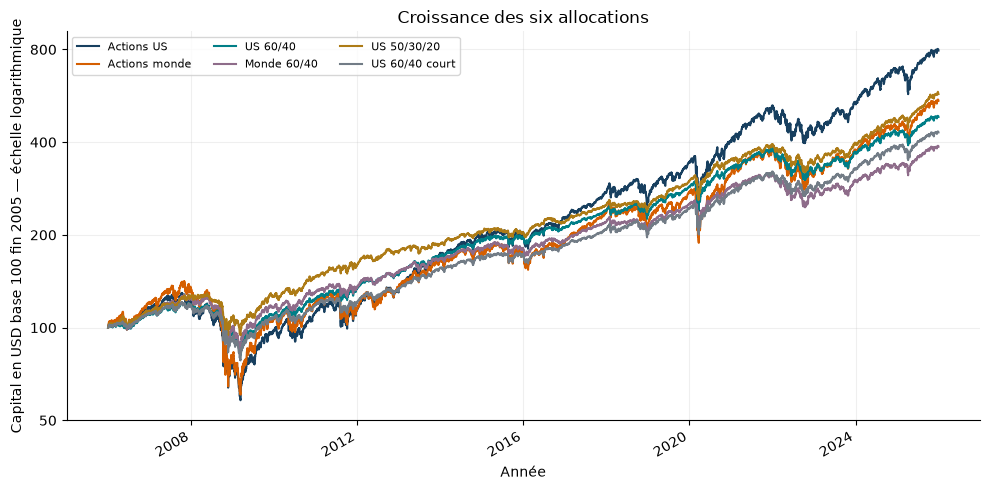

In [11]:
tracer_capital(capital)

La valeur finale ne montre pas toutes les pertes traversées. On regarde le recul depuis le **sommet propre à chaque portefeuille** : −20 % signifie un capital inférieur de 20 % à son meilleur niveau passé ; revenir à zéro signifie avoir récupéré ce sommet.


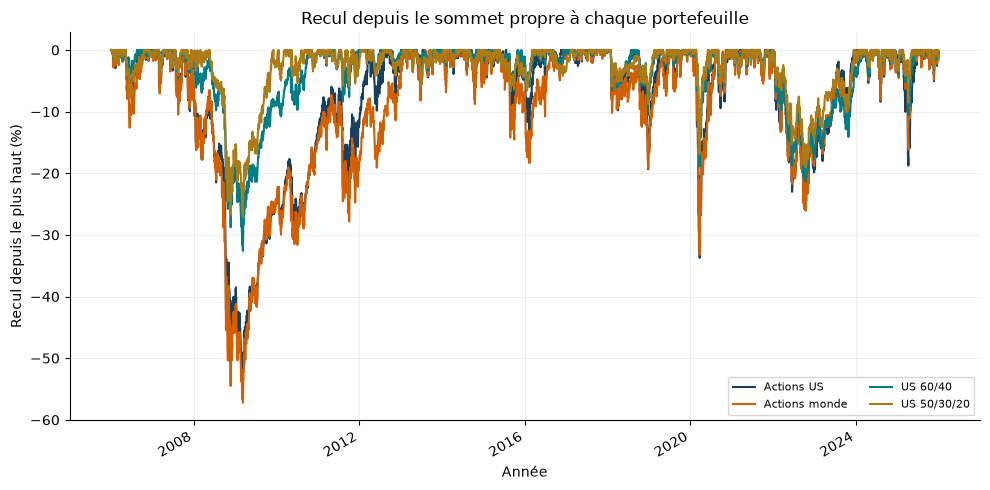

In [12]:
tracer_reculs(recul)

SPY subit un recul maximal de **55,19 %**, contre **32,58 %** pour le US 60/40 et **27,00 %** pour le 50/30/20. Les actions monde atteignent **57,22 %**. Les pertes restent importantes, même pour les allocations mixtes. On affiche quatre courbes pour la lisibilité ; le tableau couvre les six portefeuilles.

### Les séances où SPY baisse

On compare les mêmes dates : rendement moyen, proportion de séances strictement meilleures que SPY et proportion sans perte. Ces jours sont sélectionnés après coup ; les fréquences décrivent l'historique.


In [13]:
print(f"{(rendements['Actions US'] < 0).sum()} séances où SPY baisse")
pertes_en_baisse(rendements).round(2)

2242 séances où SPY baisse


,rendement moyen (%),mieux que SPY (%),sans perte (%)
Actions US,-0.82,0.00,0.00
Actions monde,-0.84,47.59,9.19
US 60/40,-0.45,86.44,11.86
Monde 60/40,-0.46,81.31,14.72
US 50/30/20,-0.38,83.32,19.54
US 60/40 court,-0.48,96.83,2.68


Sur les **2 242 séances négatives** de SPY, sa perte moyenne est de **0,822 %**, contre **0,448 %** pour le US 60/40 et **0,382 %** pour le 50/30/20. Le 60/40 fait mieux dans **86,44 %** des cas, mais évite la perte dans seulement **11,86 %** : amortir une baisse ne signifie pas l'éviter.

Les actions monde perdent en moyenne **0,844 %**. Cette comparaison favorise toutefois les allocations moins exposées à SPY ; on introduira un témoin pour préciser cet effet.

### Les cycles de baisse

On suit SPY d'un sommet à sa première récupération et on retient les cycles dont le recul atteint **10 %**. On compare tous les portefeuilles entre le sommet et le creux de SPY, aux mêmes dates. Cela diffère du recul maximal propre à chaque allocation.


In [14]:
episodes = reperer_episodes(capital["Actions US"])
performance_episodes = rendements_episodes(capital, episodes)
episodes


,sommet,creux,recuperation
0,2007-10-09,2009-03-09,2012-08-16
1,2015-07-20,2016-02-11,2016-04-18
2,2018-01-26,2018-02-08,2018-08-06
3,2018-09-20,2018-12-24,2019-04-12
4,2020-02-19,2020-03-23,2020-08-10
5,2022-01-03,2022-10-12,2023-12-13
6,2025-02-19,2025-04-08,2025-06-26


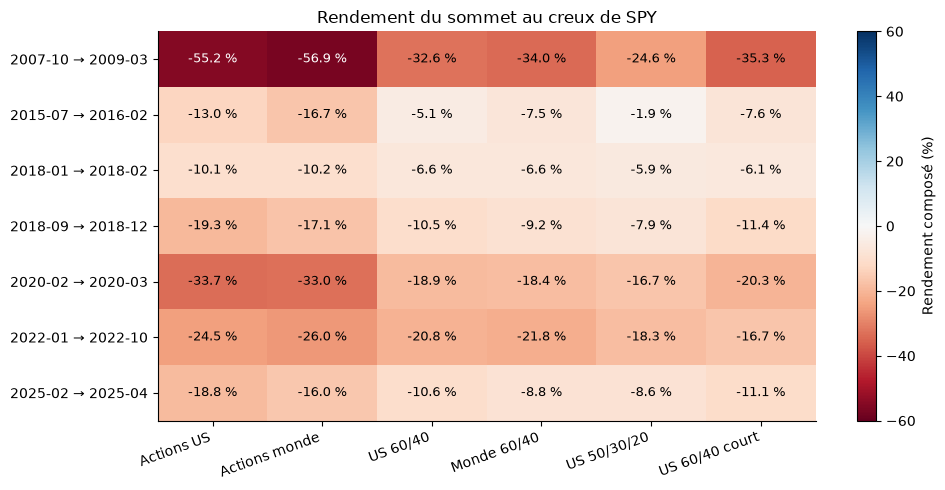

In [15]:
tracer_episodes(performance_episodes, episodes)

Les quatre allocations mixtes perdent moins que SPY dans **7 cycles sur 7**, tout en restant négatives. Les actions monde font mieux dans **3 cas sur 7**.

En 2007–2009, SPY perd **55,19 %** et le US 60/40 **32,57 %**. En 2022, ils perdent **24,50 %** et **20,77 %** : l'écart se réduit. Le 60/40 court perd **16,67 %**, ce qui invite à examiner la durée des obligations.

Les sept cycles sont récupérés fin 2025. Les rechutes avant récupération restent dans le même cycle : les corrections de 2010 et 2011 ne sont donc pas comptées séparément.


## 5. Approfondissement

### Distinguer la moindre part actions de l'apport des obligations

On construit un **témoin théorique : 60 % SPY et 40 % poche à rendement nul**, rééquilibré mensuellement. Cette poche constante ne représente ni SHY ni un placement monétaire observé.

On compare le US 60/40 à ce témoin sur les mêmes cycles. Un écart positif signifie qu'IEF a amélioré le résultat. Les cibles actions sont identiques, mais les poids effectifs peuvent dériver différemment.


In [16]:
comparaison_temoin = comparer_temoin(prix, rendements, episodes)
comparaison_temoin.set_index(["sommet", "creux"]).round(2)

,,US 60/40 (%),Témoin nul (%),écart 60/40 − témoin (points)
sommet,creux,,,
2007-10-09,2009-03-09,-32.57,-37.54,4.97
2015-07-20,2016-02-11,-5.06,-7.84,2.78
2018-01-26,2018-02-08,-6.57,-6.12,-0.45
2018-09-20,2018-12-24,-10.55,-11.79,1.24
2020-02-19,2020-03-23,-18.89,-21.08,2.20
2022-01-03,2022-10-12,-20.77,-15.11,-5.66
2025-02-19,2025-04-08,-10.56,-11.53,0.98


In [17]:
assert comparaison_temoin["sommet"].equals(episodes["sommet"])
assert comparaison_temoin["creux"].equals(episodes["creux"])
np.testing.assert_allclose(
    comparaison_temoin["écart 60/40 − témoin (points)"],
    comparaison_temoin["US 60/40 (%)"] - comparaison_temoin["Témoin nul (%)"],
)
print("Dates et écarts du témoin vérifiés")


Dates et écarts du témoin vérifiés


IEF améliore le résultat dans **cinq cycles sur sept**. En 2007–2009, le US 60/40 perd **32,57 %**, contre **37,54 %** pour le témoin, soit **4,97 points** de mieux.

En 2022, il perd **20,77 %**, contre **15,11 %** pour le témoin : les obligations dégradent le résultat de **5,66 points**, même si le portefeuille perd moins que SPY.

La protection vient donc d'une moindre part actions et d'un apport variable d'IEF. L'écart inclut aussi la dérive des poids et le rééquilibrage : ce n'est pas une mesure causale isolant la corrélation.


### Corrélations entre les actifs

La corrélation décrit leur liaison linéaire : près de +1, les rendements évoluent dans le même sens ; près de −1, en sens opposés. Une corrélation proche de zéro ne garantit ni indépendance ni protection. On la calcule sur toutes les séances.


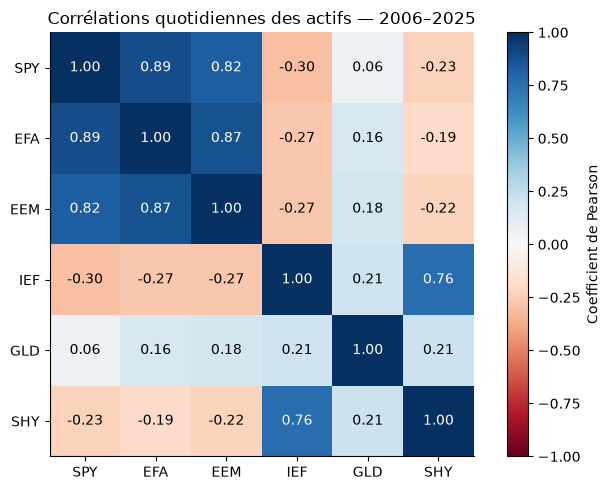

In [18]:
rendements_actifs = prix.pct_change(fill_method=None).iloc[1:]
correlations = rendements_actifs.corr()
tracer_correlations(correlations)

SPY est fortement corrélé à EFA (**0,89**) et EEM (**0,82**), ce qui éclaire la protection géographique limitée. Les corrélations avec GLD (**0,06**) et IEF (**−0,30**) sont plus faibles, sans garantir une compensation à chaque baisse.

### Contexte d'inflation

On compose les rendements par mois et on les associe à l'inflation annuelle du même mois. On compare les mois **sous 3 %** aux autres. Ce seuil est un repère descriptif, pas un choix optimisé. On regarde aussi 2008 et 2022.


In [19]:
display(contexte_inflation(rendements_actifs, inflation).round(2))
annuel_actifs = 100 * ((1 + rendements_actifs).groupby(rendements_actifs.index.year).prod() - 1)
display(annuel_actifs.loc[[2008, 2022], ["SPY", "IEF", "SHY"]].round(2))

,nombre de mois,corrélation mensuelle SPY–IEF
régime,,
inflation < 3 %,169,-0.28
inflation ≥ 3 %,70,0.25


,SPY,IEF,SHY
Date,,,
2008,-36.79,17.92,6.62
2022,-18.18,-15.16,-3.88


La corrélation mensuelle SPY–IEF vaut **−0,28** pour les **169 mois** sous 3 % d'inflation, contre **+0,25** pour les **70 autres**. Les deux actifs se compensent donc moins régulièrement dans le second groupe. Octobre 2025 est exclu ; ces corrélations mensuelles ne se comparent pas directement aux précédentes, quotidiennes.

En 2008, IEF gagne **17,92 %** et SPY perd **36,80 %**. En 2022, ils perdent **15,16 %** et **18,18 %**, tandis que SHY recule de **3,88 %**. Quand les nouvelles obligations offrent des taux plus élevés, les anciennes à taux fixe deviennent moins attractives et leur prix peut baisser, surtout à longue échéance. La [SEC explique ce risque de taux](https://www.investor.gov/introduction-investing/general-resources/news-alerts/alerts-bulletins/investor-bulletins-86).

Cela ne prouve pas que l'inflation explique seule les différences : les groupes couvrent aussi d'autres chocs. Les données peuvent être révisées et sont publiées avec retard ; on les utilise pour décrire l'historique, pas pour choisir les allocations.


## 6. Robustesse : changer la fréquence de rééquilibrage

On remplace le rééquilibrage mensuel par un rééquilibrage annuel. Le recul maximal du US 60/40 passe de **32,58 %** à **29,76 %** ; les quatre allocations mixtes restent moins touchées que SPY. Le constat ne repose donc pas uniquement sur la règle mensuelle. Cela ne démontre pas qu'une fréquence annuelle serait toujours préférable.


In [20]:
rendements_annuels = simuler_allocations(prix, "Y")
capital_annuel, recul_annuel = capital_et_recul(rendements_annuels, prix.index[0])
pd.DataFrame({"mensuel (%)": 100 * recul.min(), "annuel (%)": 100 * recul_annuel.min()}).round(2)

,mensuel (%),annuel (%)
Actions US,-55.19,-55.19
Actions monde,-57.22,-57.29
US 60/40,-32.58,-29.76
Monde 60/40,-34.66,-31.71
US 50/30/20,-27.00,-24.34
US 60/40 court,-35.29,-33.33


Les audits des sources et les contrôles du portefeuille SPY ont été exécutés dans le notebook. Le changement de fréquence examine la sensibilité du constat, sans garantir sa validité sur d'autres périodes.


In [21]:
print("Audits des sources et contrôles du notebook exécutés sans erreur")


Audits des sources et contrôles du notebook exécutés sans erreur


## 7. Réponse et limites

**Sur les allocations et la période étudiées, la diversification entre classes d'actifs amortit les pertes sans garantir le capital.** Ajouter des pays protège plus irrégulièrement. Le témoin montre que la protection combine une moindre part actions et un apport variable des obligations, défavorable notamment en 2022.

On étudie six fonds encore existants, des poids illustratifs et seulement sept cycles. Les résultats restent nominaux en dollars, sans fiscalité ni frais de transaction. Les cours ajustés de Yahoo Finance ne sont pas vérifiés auprès d'un second fournisseur. Le 50/30/20 change plusieurs expositions à la fois et le regroupement par inflation ne démontre pas de causalité.

On retient donc une protection historique **partielle et variable**, qui dépend des actifs, des poids et du critère de perte. Elle ne permet pas de prévoir la prochaine crise.
